# Retraining experiment: frozen vs periodic refit

The main evaluation trains each model **once** on data up to the cut-off and predicts the 90-day test window in one block.
Here we simulate an operational setting where the model is **re-trained every `STEP` days** on all data available at that moment.

- Same features and hyperparameters as `lgbm_forecast.py` (Optuna best params, no re-tuning) and `ridge_forecast.py` (RidgeCV re-selects alpha at each refit).
- At a refit at origin `t0` we only use rows with `time <= t0 - 144 h`: consumption arrives with a 5-day delay, so labels newer than that are not yet known.
- `STEP = 90` reproduces the frozen model under the same availability rule.

In [1]:
import numpy as np, pandas as pd, lightgbm as lgb, holidays
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DELAY_H, TEST_DAYS, SEED = 144, 90, 42
STEPS = [90, 7, 1]   # 90 = frozen, 7 = weekly refit, 1 = daily refit
BEST = dict(learning_rate=0.056568631938395224, num_leaves=69, max_depth=4, min_child_samples=14,
            subsample=0.7922543545603272, colsample_bytree=0.5202080346852211,
            reg_alpha=0.07258106225267884, reg_lambda=0.0036156052342859795, n_estimators=414)

## Data and features (identical to the two scripts)

In [2]:
df = pd.read_csv("consumption_temp.csv")
df["time"] = pd.to_datetime(df["time"], utc=True)
df = df.drop_duplicates(["time", "location"]).sort_values(["location", "time"])
df = df[~((df["location"] == "helsingfors") & (df["time"] < "2022-07-16 05:00:00+00:00"))]

def add_features(g):
    g = g.set_index("time").asfreq("h")
    g["location"] = g["location"].ffill().bfill()
    for lag in (DELAY_H, 168, 192, 336):
        g[f"lag_{lag}"] = g["consumption"].shift(lag)
    g["roll_mean_7d"] = g["consumption"].shift(DELAY_H).rolling(168).mean()
    g["roll_std_7d"] = g["consumption"].shift(DELAY_H).rolling(168).std()
    g["temp_day_mean"] = g["temperature"].groupby(g.index.date).transform("mean")
    g["temp_lag_24"] = g["temperature"].shift(24)
    for lag in (DELAY_H, 168):
        g[f"temp_diff_{lag}"] = g["temperature"] - g["temperature"].shift(lag)
    return g.reset_index()

df = pd.concat([add_features(g) for _, g in df.groupby("location")], ignore_index=True)
hol = {l: holidays.country_holidays("FI" if l.startswith("hel") else "NO") for l in df["location"].unique()}
t = df["time"]
df["hour"], df["dow"], df["month"] = t.dt.hour, t.dt.dayofweek, t.dt.month
df["is_weekend"] = (df["dow"] >= 5).astype(int)
df["is_holiday"] = [int(d in hol[l]) for d, l in zip(t.dt.date, df["location"])]
df["temp_sq"] = df["temperature"] ** 2                    # Ridge only
df["hdd"] = (15 - df["temperature"]).clip(lower=0)        # Ridge only
df = df.dropna().sort_values("time").reset_index(drop=True)
df["location"] = df["location"].astype("category")

LGB_FEATS = [c for c in df.columns if c not in ("time", "consumption", "temp_sq", "hdd")]
CAT = ["hour", "dow", "month"]
NUM = [c for c in df.columns if c not in ["time", "location", "consumption", *CAT]]
cut = df["time"].max() - pd.Timedelta(days=TEST_DAYS)
print(len(df), "rows | test starts after", cut)

47446 rows | test starts after 2023-01-02 21:00:00+00:00


## Fit/predict functions and rolling-origin loop

In [3]:
def fit_predict_lgbm(tr, te):
    m = lgb.LGBMRegressor(objective="regression", subsample_freq=1, verbosity=-1, random_state=SEED, **BEST)
    return m.fit(tr[LGB_FEATS], tr["consumption"]).predict(te[LGB_FEATS])

def fit_predict_ridge(tr, te):
    out = pd.Series(index=te.index, dtype=float)
    for loc, d_te in te.groupby("location", observed=True):
        d_tr = tr[tr["location"] == loc]
        cv = TimeSeriesSplit(n_splits=4, test_size=len(d_tr) // 6, gap=24 * 6)
        m = make_pipeline(ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
                                             ("num", StandardScaler(), NUM)]),
                          RidgeCV(alphas=np.logspace(-3, 3, 25), cv=cv, scoring="neg_mean_absolute_error"))
        out[d_te.index] = m.fit(d_tr[CAT + NUM], d_tr["consumption"]).predict(d_te[CAT + NUM])
    return out.values

def rolling(fit_predict, step_days):
    parts = []
    for t0 in pd.date_range(cut, df["time"].max(), freq=f"{step_days}D"):
        tr = df[df["time"] <= t0 - pd.Timedelta(hours=DELAY_H)]          # labels known at t0
        te = df[(df["time"] > t0) & (df["time"] <= t0 + pd.Timedelta(days=step_days))]
        if len(te):
            parts.append(te.assign(pred=fit_predict(tr, te)))
    return pd.concat(parts)

res = {}
for name, fp in [("LightGBM", fit_predict_lgbm), ("Ridge", fit_predict_ridge)]:
    for step in STEPS:
        res[(name, step)] = rolling(fp, step)
        print(f"{name:8s} step={step:2d} days done")

LightGBM step=90 days done
LightGBM step= 7 days done
LightGBM step= 1 days done
Ridge    step=90 days done
Ridge    step= 7 days done
Ridge    step= 1 days done


## Results

In [4]:
def metrics(d):
    e = d["pred"] - d["consumption"]
    return pd.Series({"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
                      "WAPE_%": 100 * e.abs().sum() / d["consumption"].sum(), "bias": e.mean()})

label = {90: "frozen", 7: "weekly refit", 1: "daily refit"}
summary = pd.DataFrame({(m, label[s]): metrics(d) for (m, s), d in res.items()}).T.round(4)
for m in ["LightGBM", "Ridge"]:
    summary.loc[m, "ΔMAE_vs_frozen_%"] = (100 * (summary.loc[m, "MAE"] / summary.loc[(m, "frozen"), "MAE"] - 1)).round(1).values
summary

MAE    RMSE  WAPE_%    bias  ΔMAE_vs_frozen_%
LightGBM frozen        0.3002  0.4320  5.4174  0.0665               0.0
         weekly refit  0.2710  0.4101  4.8890  0.0734              -9.7
         daily refit   0.2731  0.4126  4.9274  0.0671              -9.0
Ridge    frozen        0.3051  0.4886  5.5054 -0.1432               0.0
         weekly refit  0.2732  0.4504  4.9286 -0.0445             -10.5
         daily refit   0.2761  0.4621  4.9817 -0.0261              -9.5

In [5]:
by_city = pd.DataFrame({(m, label[s]): d.groupby("location", observed=True).apply(lambda x: (x["pred"] - x["consumption"]).abs().mean())
                        for (m, s), d in res.items()}).round(3)
by_city

LightGBM                           Ridge                         
              frozen weekly refit daily refit frozen weekly refit daily refit
location                                                                     
bergen         0.210        0.197       0.208  0.191        0.203       0.207
helsingfors    0.214        0.129       0.119  0.178        0.116       0.113
oslo           0.626        0.623       0.625  0.810        0.690       0.688
stavanger      0.409        0.375       0.376  0.313        0.313       0.337
tromsø         0.121        0.100       0.103  0.097        0.109       0.112
trondheim      0.221        0.202       0.208  0.242        0.208       0.200

In [6]:
by_month = pd.DataFrame({(m, label[s]): d.groupby(d["time"].dt.month).apply(lambda x: (x["pred"] - x["consumption"]).abs().mean())
                         for (m, s), d in res.items()}).round(3)
by_month.index.name = "month"
by_month

LightGBM                           Ridge                         
        frozen weekly refit daily refit frozen weekly refit daily refit
month                                                                  
1        0.310        0.295       0.302  0.347        0.316       0.348
2        0.259        0.230       0.229  0.275        0.243       0.216
3        0.317        0.280       0.280  0.276        0.235       0.238
4        0.476        0.353       0.363  0.572        0.669       0.672

Daily portfolio MAE over the test window: shows *when* retraining helps (e.g. once February/March data enter the training set).

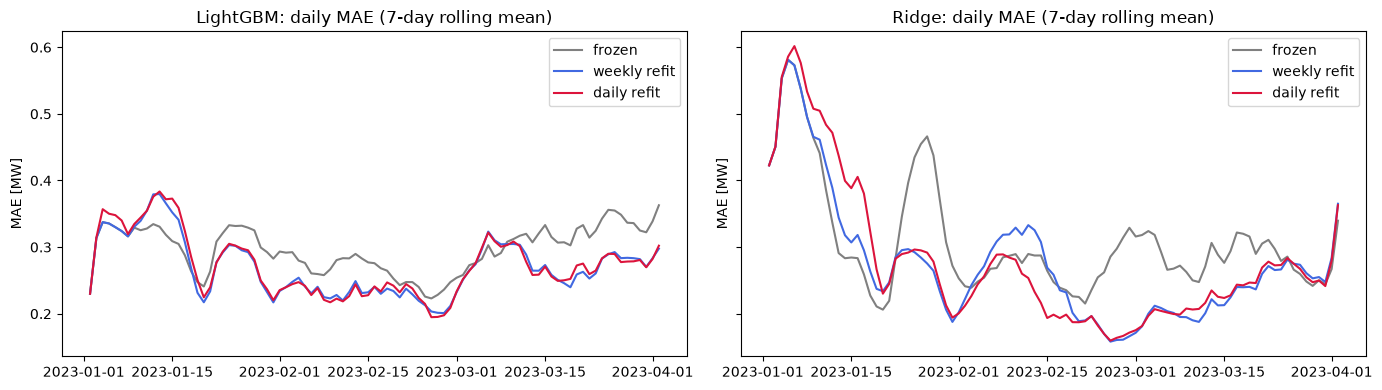

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, m in zip(axes, ["LightGBM", "Ridge"]):
    for s, c in zip(STEPS, ["gray", "royalblue", "crimson"]):
        d = res[(m, s)]
        daily = d.assign(ae=(d["pred"] - d["consumption"]).abs()).groupby(d["time"].dt.date)["ae"].mean()
        ax.plot(pd.to_datetime(daily.index), daily.rolling(7, min_periods=1).mean(), label=label[s], color=c)
    ax.set_title(f"{m}: daily MAE (7-day rolling mean)"); ax.set_ylabel("MAE [MW]"); ax.legend()
plt.tight_layout(); plt.show()

Hourly MAE profile for all models and training regimes (colour = model, line style = retraining frequency).

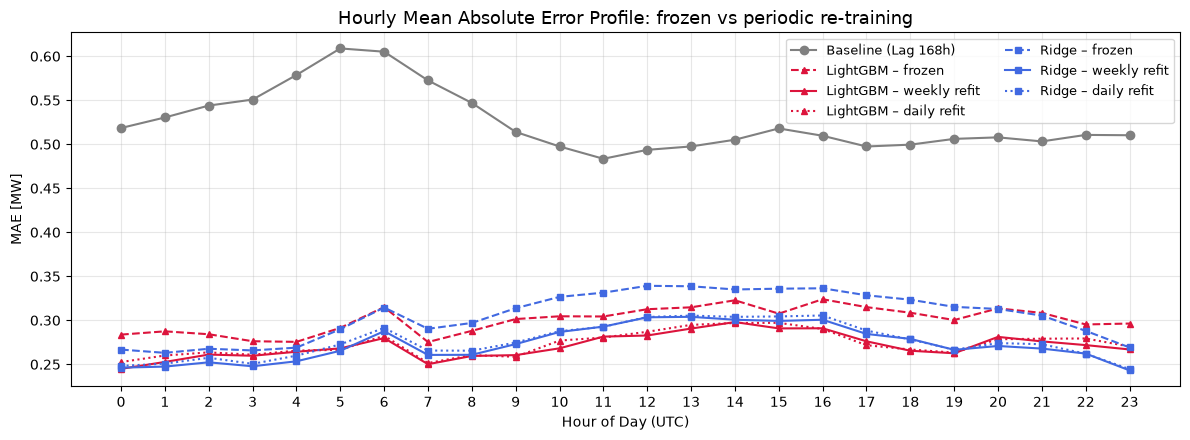

In [8]:
test_rows = res[("LightGBM", 90)]
hourly = {("Baseline", ""): (test_rows["lag_168"] - test_rows["consumption"]).abs().groupby(test_rows["hour"]).mean()}
for (m, s), d in res.items():
    hourly[(m, label[s])] = (d["pred"] - d["consumption"]).abs().groupby(d["hour"]).mean()

style = {"frozen": "--", "weekly refit": "-", "daily refit": ":"}
color = {"LightGBM": "crimson", "Ridge": "royalblue"}
marker = {"LightGBM": "^", "Ridge": "s"}

plt.figure(figsize=(12, 4.5))
plt.plot(hourly[("Baseline", "")], marker="o", color="gray", label="Baseline (Lag 168h)")
for (m, s), v in hourly.items():
    if m != "Baseline":
        plt.plot(v, color=color[m], ls=style[s], marker=marker[m], markersize=4, label=f"{m} – {s}")
plt.xticks(range(24)); plt.xlabel("Hour of Day (UTC)"); plt.ylabel("MAE [MW]")
plt.title("Hourly Mean Absolute Error Profile: frozen vs periodic re-training", fontsize=13)
plt.legend(ncol=2, fontsize=9); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("hourly_mae_retraining.png", dpi=200); plt.show()

In [9]:
# save daily-refit predictions for the comparison notebook / KPIs
for m in ["LightGBM", "Ridge"]:
    res[(m, 1)][["time", "location", "consumption", "pred"]].to_csv(f"{m.lower()}_daily_refit_predictions.csv", index=False)
summary.to_csv("retraining_summary.csv")